In [13]:
from datetime import date

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import polars as pl
import polars.selectors as cs

In [4]:
import alleg.process_data as data
import alleg.report as report

In [3]:
report.NextInspections.count().show()

device_id,next_date
u64,u64
39302,34232


In [5]:
report.NeverInspectedDeviceIds.count().show()

device_id
u64
5070


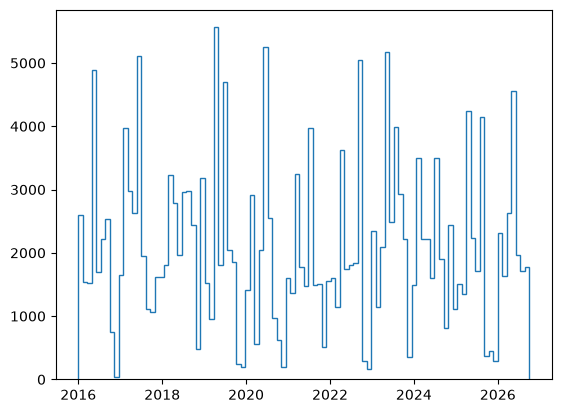

In [7]:
plt.hist(
    data.Inspections.select(
        pl.col('date').dt.truncate('1mo'),
    ).collect(),
    bins=100,
    histtype='step',
);

In [11]:
# output of matplotlib.dates.date2num for the date range of interest
# mydays = range(16801, 22645, 30)
mydays = range(16801, 22645, 60)

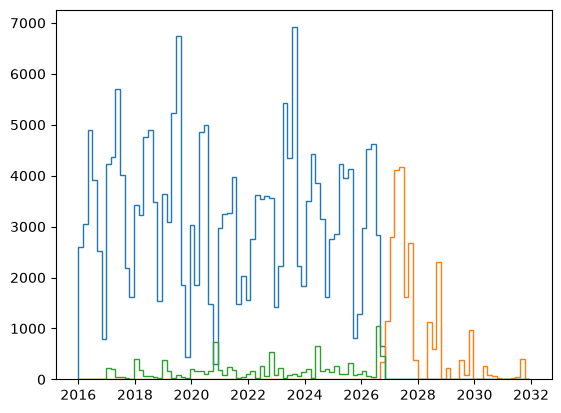

In [14]:
plt.hist(
    data.Inspections.select(pl.col('date').dt.truncate('1mo')).collect(),
    bins=mydays,
    histtype='step',
);
plt.hist(
    report.NextInspections.filter(
        pl.col('next_date') > date.today(),
    ).select(
        cs.date().dt.truncate('1mo'),
    ).collect(),
    bins=mydays,
    histtype='step',
);
plt.hist(
    report.NextInspections.filter(
        pl.col('next_date') < date.today(),
    ).select(
        cs.date().dt.truncate('1mo'),
    ).collect(),
    bins=mydays,
    histtype='step',
);

blue - Inspections that happened  
green - Inspections that didn't happen  
orange - Inspections that need to happen

In [15]:
data.Inspections.group_by('store_id','date').len().sort('len',descending=True).show(10)

store_id,date,len
i64,date,u64
40000,2019-07-30,1350
31520,2017-06-20,1335
32698,2024-12-12,1333
32542,2022-10-13,1315
31520,2017-04-27,1277
40000,2018-10-23,1255
31520,2017-02-03,1238
31520,2017-11-27,1221
32507,2023-09-21,1184


In [16]:
data.Devices.filter(pl.col('store_id').is_in([40000,31520])).show(100)

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
11556897,10234,31520,"""PARKING METER""","""TIMING""","""POM APM""","""SD-123""","""0820""",null,null,null,"""36 MONTH""","""BROWNSVILLE RD 2600 THRU 2900""",true,"""36mo"""
11556898,10235,40000,"""PARKING METER""","""TIMING""",null,null,null,null,null,null,"""36 MONTH""",null,false,"""36mo"""
11556899,10236,40000,"""PARKING METER""","""TIMING""",null,null,"""01734""","""MURRAY 1602""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556900,10237,40000,"""PARKING METER""","""TIMING""",null,null,"""01735""","""MURRAY 1701""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556901,10238,40000,"""PARKING METER""","""TIMING""",null,null,"""01740""","""MURRAY 1702""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556902,10239,40000,"""PARKING METER""","""TIMING""",null,null,"""01761""","""MURRAY 1704""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556903,10240,40000,"""PARKING METER""","""TIMING""",null,null,"""01738""","""MURRAY 1801""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556904,10241,40000,"""PARKING METER""","""TIMING""",null,null,"""01760""","""MURRAY 1802""",null,null,"""36 MONTH""",null,false,"""36mo"""
11556905,10242,40000,"""PARKING METER""","""TIMING""",null,null,"""01736""","""MURRAY 1804""",null,null,"""36 MONTH""",null,false,"""36mo"""


In [17]:
data.Inspections.group_by('store_id','date').len().sort('len',descending=True).filter(pl.col('store_id').is_in([40000,31520])).sort('date').show(100)

store_id,date,len
i64,date,u64
31520,2016-05-06,1151
31520,2017-02-03,1238
31520,2017-03-03,4
31520,2017-04-27,1277
31520,2017-06-20,1335
31520,2017-11-27,1221
40000,2018-05-22,827
40000,2018-07-27,890
40000,2018-10-23,1255


In [18]:
data.Stores.filter(pl.col('business_phone')=="(412) 560-7275").show()

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2037617,31520,"""PGH PARKING AUTHORITY""","""232 BLVD OF THE ALLIES""","""PITTSBURGH""","""PA""","""15222""","""DOWNTOWN""",null,-80.002647,40.438476,"""(412) 560-7275""",null,false,false,false,true,false,null,null,"""PITTSBURGH"""
2038922,40000,"""PITTSBURGH PARKING AUTHORITY""","""232 BLVD OF THE ALLIES""","""PITTSBURGH""","""PA""","""15222""","""DOWNTOWN""",null,-80.002647,40.438476,"""(412) 560-7275""",null,false,false,false,true,false,null,null,"""PITTSBURGH"""


In [19]:
data.Stores.filter(pl.col('store_id').is_in([40000,31520,32698,32542,31520])).show()

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2037617,31520,"""PGH PARKING AUTHORITY""","""232 BLVD OF THE ALLIES""","""PITTSBURGH""","""PA""","""15222""","""DOWNTOWN""",null,-80.002647,40.438476,"""(412) 560-7275""",null,false,false,false,true,false,null,null,"""PITTSBURGH"""
2038332,32542,"""WILKINSBURG BORO""","""605 ROSS AVE""","""PITTSBURGH""","""PA""","""15221""","""WILKINSBURG""",null,-79.88585,40.443354,"""(412) 244-2900""",null,false,false,false,true,false,null,null,"""WILKINSBURG"""
2038461,32698,"""MT LEBANON PARKING""","""788 WASHINGTON RD""","""PITTSBURGH""","""PA""","""15228""","""MT LEBANON""",null,-80.046279,40.378221,"""(412) 343-4422""",null,false,false,false,true,false,null,null,"""MTLEBANON"""
2038922,40000,"""PITTSBURGH PARKING AUTHORITY""","""232 BLVD OF THE ALLIES""","""PITTSBURGH""","""PA""","""15222""","""DOWNTOWN""",null,-80.002647,40.438476,"""(412) 560-7275""",null,false,false,false,true,false,null,null,"""PITTSBURGH"""


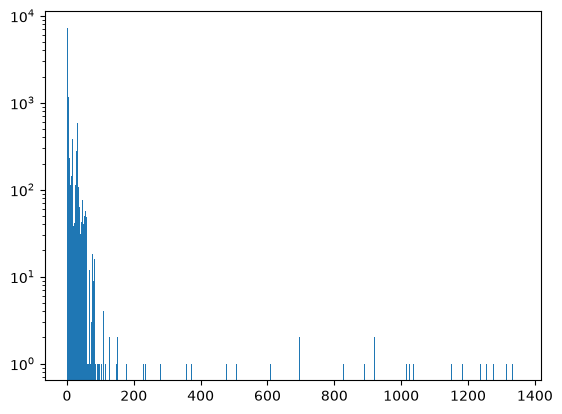

In [20]:
plt.hist(data.Inspections.group_by('store_id','date').len().select('len').collect(),bins=1000);
plt.yscale('log')

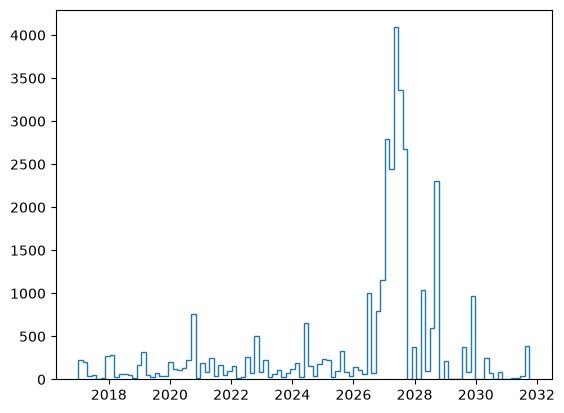

In [21]:
plt.hist(
    report.NextInspections.select(pl.col('next_date').dt.truncate('1mo')).collect(),
    bins=100,
    histtype='step',
);

In [22]:
data.Devices.show()

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
11546635,1,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546636,2,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""2""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546637,3,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406954""","""3""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546638,4,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406954""","""4""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546639,5,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406955""","""5""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""


In [23]:
report.ActiveDeviceIds.join(report.LastInspections, 'device_id').sort('date').show()

device_id,_id,inspection_id,store_id,date,result,reinspection
i64,i64,i64,i64,date,cat,cat
21463,89538411,53434,40318,2016-04-22,"""Pass""","""No"""
21460,89538414,53437,40318,2016-04-22,"""Pass""","""No"""
21462,89538413,53436,40318,2016-04-22,"""Pass""","""No"""
21461,89538412,53435,40318,2016-04-22,"""Pass""","""No"""
21464,89538415,53438,40319,2016-04-22,"""Pass""","""No"""


In [24]:
data.Inspections.sort('date').group_by('device_id', maintain_order=True).last().show()

device_id,_id,inspection_id,store_id,date,result,reinspection
i64,i64,i64,i64,date,cat,cat
14970,89648317,164137,40048,2022-01-04,"""Pass""","""No"""
14933,89665232,181064,40044,2023-01-04,"""Pass""","""No"""
13079,89687580,203413,32896,2024-01-08,"""Pass""","""No"""
13509,89550467,65496,32044,2017-01-09,"""Pass""","""No"""
11193,89532988,47997,30532,2016-01-05,"""Pass""","""No"""


In [25]:
data.Inspections.with_columns(last=pl.col('date').last().over('device_id',order_by='date')).show()

_id,inspection_id,store_id,device_id,date,result,reinspection,last
i64,i64,i64,i64,date,cat,cat,date
89532961,38362,30460,5445,2016-05-03,"""Pass""","""No""",2017-07-28
89532962,47971,31879,9013,2016-01-07,"""Pass""","""No""",2026-08-31
89532963,47972,30416,6893,2016-01-07,"""Pass""","""Yes""",2026-04-28
89532964,47973,31699,8346,2016-01-07,"""Pass""","""Yes""",2026-06-04
89532965,47974,32341,14011,2016-01-07,"""Pass""","""No""",2017-02-02


In [26]:
data.Inspections.select(pl.col('date').last())

In [27]:
report.Inspection_Interval.join(
    report.ActiveDeviceIds, 'device_id',
).filter(pl.col('next_date').is_null()).show()

_id,inspection_id,store_id,device_id,date,result,reinspection,_id_right,store_id_right,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset,next_date,next_date_upcoming,interval,interval_upcoming
i64,i64,i64,i64,date,cat,cat,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str,date,date,duration[μs],duration[μs]
89543577,58600,32541,21648,2016-05-26,"""Pass""","""No""",11563884,32541,"""PARKING METER""","""TIMING""","""DUNCAN INDUSTRIES""","""8502""","""0189""",null,null,null,"""60 MONTH""",null,false,"""60mo""",null,2026-10-31,null,3810d
89543586,58609,32541,21695,2016-05-26,"""Pass""","""No""",11563893,32541,"""PARKING METER""","""TIMING""","""DUNCAN INDUSTRIES""",null,"""0178""",null,null,null,"""60 MONTH""",null,false,"""60mo""",null,2026-10-31,null,3810d
89543703,58726,32541,21679,2016-05-26,"""Pass""","""No""",11564673,32541,"""PARKING METER""","""TIMING""","""DUNCAN INDUSTRIES""",null,"""0130""",null,null,null,"""60 MONTH""",null,false,"""60mo""",null,2026-10-31,null,3810d
89543726,58749,32541,21831,2016-05-26,"""Pass""","""No""",11564696,32541,"""PARKING METER""","""TIMING""","""DUNCAN INDUSTRIES""","""5090-9""","""3243""",null,null,null,"""60 MONTH""",null,false,"""60mo""",null,2026-10-31,null,3810d
89543823,58846,32541,21817,2016-05-26,"""Pass""","""No""",11564958,32541,"""PARKING METER""","""TIMING""","""DUNCAN INDUSTRIES""",null,"""21124""",null,null,null,"""60 MONTH""",null,false,"""60mo""",null,2026-10-31,null,3810d


In [28]:
data.Stores.filter(
    pl.col('oob').not_(),
    pl.col('scale'),
).join(data.Inspections, 'store_id', how='anti').show(1000)

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2039763,40842,"""TARGET""","""4801 MCKNIGHT RD""",null,"""PA""","""15237""","""ROSS TWP""",null,-80.00779,40.525416,"""(412) 536-1807""",null,true,false,true,false,false,null,null,"""ROSS"""
2036682,30330,"""ONE STOP CONVENIENCE""","""3601 BLVD OF THE ALLIES""","""PITTSBURGH""","""PA""","""15213""","""OAKLAND""","""SOUTH OAKLAND""",-79.954209,40.434768,"""412-621-4539""",null,false,false,true,false,false,null,null,"""PITTSBURGH"""
2039109,40187,"""KEYSTONE IRON & METAL CO""","""4903 E CARSON ST""","""PITTSBURGH""","""PA""","""15207""",null,"""HAZELWOOD""",-79.935354,40.394457,"""412-462-1520""",null,false,false,true,false,false,null,null,"""PITTSBURGH"""
2038236,32348,"""ISALYS""","""2002 LINCOLN BLVD""","""ELIZABETH""","""PA""","""15037""","""ELIZABETH""",null,-79.874797,40.278942,"""(412) 384-3329""",null,false,false,true,false,false,null,null,"""LINCOLN"""
2038415,32640,"""NINJA ENTERTAINMENT""","""404 SMITHFIELD ST""","""PITTSBURGH""","""PA""","""15222""","""DOWNTOWN""",null,-79.999299,40.438854,"""412-979-1515""",null,false,false,true,false,false,null,null,"""PITTSBURGH"""
2038938,40016,"""FROZEN YOGURT & SMOOTHIES""","""1800 GOLDEN MILE HWY""","""PITTSBURGH""","""PA""","""15239""",null,null,-79.713351,40.446153,"""724-325-5683""",null,false,false,true,false,false,null,null,"""PLUM"""
2037126,30888,"""BURTONS TOTAL PET""","""4960 ROUTE 8""","""ALLISON PARK""","""PA""","""15101""","""GIBSONIA""",null,-79.944057,40.603014,"""724-444-8103""",null,false,false,true,false,false,null,"""SHOPPERS PLAZA""","""HAMPTON"""
2039941,41020,"""WONDERFILL LOW WASTE MARKET""","""370 BROADMOOR AVE""",null,"""PA""","""15228""","""MT LEBANON""",null,-80.031816,40.37661,"""(412) 502-9101""",null,false,false,true,false,false,null,null,null
2040184,41263,"""THE BOOK DELI""","""601 E Warrington Ave""",null,"""PA""","""15210""","""MT OLIVER""",null,null,null,"""(412) 995-0223""",null,false,false,true,false,false,null,null,null


In [29]:
data.Stores.filter(
    pl.col('oob').not_(),
    pl.col('price_verification') | pl.col('fuel_dispenser') | pl.col('scale') | pl.col('timing'),
).join(data.Inspections, 'store_id', how='anti').show(1000)

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2036467,30042,"""PIERCING PAGODA BANTER""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 372-6346""",null,true,false,false,false,false,null,"""MONROEVILLE MALL""","""MONROEVILLE"""
2036472,30048,"""KIDS FOOT LOCKER""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 666-0618""",null,true,false,false,false,false,null,"""MONROEVILLE MALL""","""MONROEVILLE"""
2036482,30063,"""HOT TOPIC""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 372-5140""",null,true,false,false,false,false,null,"""MONROEVILLE MALL""","""MONROEVILLE"""
2036500,30090,"""BEST BUY""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 856-7344""",null,true,false,false,false,false,null,"""MONROEVILLE MALL ANNEX""","""MONROEVILLE"""
2036507,30099,"""GUITAR CENTER""","""384 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.794734,40.426506,"""(412) 372-8800""",null,true,false,false,false,false,null,"""MONROEVILLE MALL ANNEX""","""MONROEVILLE"""
2036509,30102,"""HARBOR FREIGHT TOOLS""","""145 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.799828,40.430934,"""(412) 373-3061""",null,true,false,false,false,false,null,"""MONROEVILLE MALL ANNEX""","""MONROEVILLE"""
2036518,30114,"""MARSHALLS""","""4100 WILLIAM PENN HWY""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.768809,40.437261,"""(412) 372-7410""",null,true,false,false,false,false,"""UNIT 12""","""MIRACLE MILE SHOPPING CENTER""","""MONROEVILLE"""
2036534,30135,"""MICHAELS""","""5070 WILLIAM PENN HWY""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.707847,40.42692,"""(412) 387-1698""",null,true,false,false,false,false,null,null,"""MONROEVILLE"""
2036536,30137,"""LOWES""","""4200 WILLIAM PENN HWY""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.762662,40.437189,"""(412) 717-9122""",null,true,false,false,false,false,null,null,"""MONROEVILLE"""


In [30]:
report.Inspection_Interval.join(report.ActiveDeviceIds, 'device_id').select("device_group").collect().unique()

device_group
cat
"""SCALE"""
"""TIMING"""
"""FUEL DISPENSER"""
"""MISCELLANEOUS"""


In [31]:
data.Devices.count().collect()

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
u64,u64,u64,u64,u64,u64,u64,u64,u64,u64,u64,u64,u64,u64,u64
39302,39302,39302,39301,39302,38824,11887,39085,20740,13439,9331,39300,13789,39302,39300


In [32]:
data.Stores.filter(store_id=32797).show(100)

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2038546,32797,"""BURTONS TOTAL PET""","""1635 C S BRADDOCK AVE""","""PITTSBURGH""","""PA""","""15218""","""EDGEWOOD""",null,-79.894523,40.433005,"""412-342-0110""",null,false,false,false,false,true,null,"""EDGEWOOD TOWNE CENTRE""","""EDGEWOOD"""


In [33]:
report.Inspection_Interval.filter(device_id=10681).show(100)

_id,inspection_id,store_id,device_id,date,result,reinspection,_id_right,store_id_right,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset,next_date,next_date_upcoming,interval,interval_upcoming
i64,i64,i64,i64,date,cat,cat,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str,date,date,duration[μs],duration[μs]


In [34]:
report.Inspection_Interval.filter(deleted=False).sort('interval_upcoming', descending=True).show()

_id,inspection_id,store_id,device_id,date,result,reinspection,_id_right,store_id_right,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset,next_date,next_date_upcoming,interval,interval_upcoming
i64,i64,i64,i64,date,cat,cat,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str,date,date,duration[μs],duration[μs]
89538411,53434,40318,21463,2016-04-22,"""Pass""","""No""",11566707,40318,"""AIR/VACUUM HOSE""","""TIMING""","""FRAGRAMATICS""","""NSN""","""78860""",null,null,null,"""60 MONTH""","""VAC-4""",false,"""60mo""",null,2026-10-31,null,3844d
89538415,53438,40319,21464,2016-04-22,"""Pass""","""No""",11563807,40319,"""AIR/VACUUM HOSE""","""TIMING""","""JE ADAMS IND""",null,"""8423-1""",null,null,null,"""60 MONTH""","""V-1""",false,"""60mo""",null,2026-10-31,null,3844d
89538413,53436,40318,21462,2016-04-22,"""Pass""","""No""",11566747,40318,"""AIR/VACUUM HOSE""","""TIMING""","""FRAGRAMATICS""","""NSN""","""90187""",null,null,null,"""60 MONTH""","""VAC-3""",false,"""60mo""",null,2026-10-31,null,3844d
89538414,53437,40318,21460,2016-04-22,"""Pass""","""No""",11568268,40318,"""AIR/VACUUM HOSE""","""TIMING""","""FRAGRAMATICS""","""NSN""","""90186""",null,null,null,"""60 MONTH""","""VAC-1""",false,"""60mo""",null,2026-10-31,null,3844d
89538412,53435,40318,21461,2016-04-22,"""Pass""","""No""",11566738,40318,"""AIR/VACUUM HOSE""","""TIMING""","""FRAGRAMATICS""","""NSN""","""81343""",null,null,null,"""60 MONTH""","""VAC-2""",false,"""60mo""",null,2026-10-31,null,3844d


In [35]:
data.Devices.show()

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
11546635,1,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546636,2,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""2""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546637,3,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406954""","""3""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546638,4,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406954""","""4""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546639,5,33113,"""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406955""","""5""","""S-93""",null,"""12 MONTH""",null,false,"""12mo"""


Aside, quick spot check https://qlever.dev/osm-planet/Pgayxf

In [36]:
data.Stores.filter(oob=False).group_by('store_name').len().sort('len',descending=True).show()

store_name,len
str,u64
"""SUNOCO""",90
"""DOLLAR GENERAL""",62
"""BP""",44
"""GIANT EAGLE""",40
"""DOLLAR TREE""",37


In [37]:
data.Devices.filter(device_type='POSTAL').select('store_id').join(Stores, 'store_id').show()

store_id,_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
30220,2036602,"""SHIPPING DEPOT""","""4960 ROUTE 8""","""ALLISON PARK""","""PA""","""15101""","""ALLISON PARK""",null,-79.944057,40.603014,"""(724) 443-8711""",null,false,false,true,false,false,null,"""SHOPPERS PLAZA""","""HAMPTON"""
30318,2036672,"""THE UPS STORE""","""1525 PARK MANOR BLVD""","""PITTSBURGH""","""PA""","""15205""","""ROBINSON TWP""",null,-80.164143,40.45464,"""(412) 787-5912""",null,false,false,true,false,false,null,"""ROBINSON TOWNE CENTER""","""ROBINSON"""
32222,2038142,"""THE UPS STORE""","""2366 GOLDEN MILE HWY""","""PITTSBURGH""","""PA""","""15239""","""PLUM BORO""",null,-79.704707,40.462713,"""(724) 733-1111""",null,false,false,true,false,false,null,null,"""PLUM"""
32222,2038142,"""THE UPS STORE""","""2366 GOLDEN MILE HWY""","""PITTSBURGH""","""PA""","""15239""","""PLUM BORO""",null,-79.704707,40.462713,"""(724) 733-1111""",null,false,false,true,false,false,null,null,"""PLUM"""
32849,2038593,"""KENNEDY COPY & PRINT SERVICES""","""500 PINE HOLLOW RD""","""MC KEES ROCKS""","""PA""","""15136""","""KENNEDY TWP""",null,-80.098041,40.47462,"""412-875-5716""",null,false,false,false,false,true,null,"""KENMAWR SHOPPING CENTER""","""KENNEDY"""


In [38]:
data.Devices.filter(
    device_group="FUEL DISPENSER",
    inspection_cycle="60 MONTH",
).collect().to_dicts()

[{'_id': 11573708,
  'device_id': 26372,
  'store_id': 32745,
  'device_type': 'GASOLINE',
  'device_group': 'FUEL DISPENSER',
  'make': 'DUNCAN INDUSTRIES',
  'model': '5099-9',
  'serial_number': '807',
  'pump': 'W 8TH AVE - REJECTED - BAD FLAG',
  'grade': None,
  'capacity': None,
  'inspection_cycle': '60 MONTH',
  'remarks': None,
  'deleted': False,
  'offset': '60mo'}]

In [39]:
data.Devices.join(data.Inspections, 'device_id', how='anti').collect()

_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
11546700,66,31516,"""GASOLINE""","""FUEL DISPENSER""","""TOKHEIM""",null,"""903001""",null,"""PR-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546701,67,31516,"""GASOLINE""","""FUEL DISPENSER""","""TOKHEIM""",null,"""903001""",null,"""PR-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546702,68,31516,"""GASOLINE""","""FUEL DISPENSER""","""TOKHEIM""",null,"""903002""",null,"""PR-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546703,69,31516,"""GASOLINE""","""FUEL DISPENSER""","""TOKHEIM""",null,"""903002""",null,"""PR-93""",null,"""12 MONTH""",null,false,"""12mo"""
11546704,70,31516,"""GASOLINE""","""FUEL DISPENSER""","""TOKHEIM""",null,"""903003""",null,"""PR-93""",null,"""12 MONTH""",null,false,"""12mo"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11585924,39819,31891,"""AIR/VACUUM HOSE""","""TIMING""",null,null,null,null,null,null,"""60 MONTH""",null,false,"""60mo"""
11585925,39820,31893,"""AIR/VACUUM HOSE""","""TIMING""",null,null,null,null,null,null,"""60 MONTH""",null,false,"""60mo"""
11585926,39821,40458,"""AIR/VACUUM HOSE""","""TIMING""",null,null,null,null,null,null,"""60 MONTH""",null,false,"""60mo"""


In [40]:
data.Devices.filter(deleted=False).group_by('device_group','inspection_cycle').len().collect().filter(pl.col('len')>0).show(100)

device_group,inspection_cycle,len
cat,str,u64
"""FUEL DISPENSER""","""12 MONTH""",12508
"""TIMING""","""36 MONTH""",2870
"""TIMING""","""60 MONTH""",11723
"""TIMING""","""12 MONTH""",627
"""SCALE""","""12 MONTH""",6058
"""TIMING""","""OTHER""",1
"""TIMING""",null,1
"""SCALE""","""36 MONTH""",1
"""SCALE""",null,1


In [41]:
report.Inspection_Interval.filter(
    pl.col('reinspection') == 'No',
    # pl.col("device_group").is_in(["SCALE", "FUEL DISPENSER"]),
    datetime.timedelta(days=0) < pl.col('interval'),
    pl.col('interval') < datetime.timedelta(days=800),
    pl.col('deleted').not_(),
# ).sql("select * exclude(device_group),device_group||'/'||inspection_cycle from self",
).with_columns(
    cs.duration().dt.total_days(),
).collect().to_pandas()

,_id,inspection_id,store_id,device_id,date,result,reinspection,_id_right,store_id_right,device_type,...,grade,capacity,inspection_cycle,remarks,deleted,offset,next_date,next_date_upcoming,interval,interval_upcoming
0,89533712,48721,32136,12137,2016-01-20,Pass,No,11558783,32136,DIGITAL,...,NaN,30 LB,12 MONTH,NaN,False,12mo,2017-02-15,2017-02-15,392,392
1,89533827,48836,32547,12397,2016-01-19,Pass,No,11559041,32547,DIGITAL,...,NaN,30 LB,12 MONTH,NaN,False,12mo,2017-01-17,2017-01-17,364,364
2,89533888,48897,40252,19943,2016-01-25,Pass,No,11581838,40252,PLATFORM,...,NaN,15 LB,12 MONTH,NaN,False,12mo,2017-02-23,2017-02-23,395,395
3,89533989,49008,32326,13918,2016-01-25,Pass,No,11560540,32326,DIGITAL,...,NaN,30 LB,12 MONTH,NaN,False,12mo,2017-02-23,2017-02-23,395,395
4,89534022,49041,30301,13613,2016-01-27,Pass,No,11560244,30301,DIGITAL,...,NaN,30 LB,12 MONTH,NaN,False,12mo,2017-01-23,2017-01-23,362,362
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140231,89741412,257499,31788,5207,2026-08-17,Fail,No,11551859,31788,GASOLINE,...,P-93,NaN,12 MONTH,NaN,False,12mo,2026-09-25,2026-09-25,39,39
140232,89741530,257617,31606,4892,2026-08-18,Fail,No,11551544,31606,GASOLINE,...,R-87,NaN,12 MONTH,NaN,False,12mo,2026-09-11,2026-09-11,24,24
140233,89741641,257728,40555,30099,2026-08-19,Pass,No,11583170,40555,GASOLINE,...,R-87,NaN,12 MONTH,NaN,False,12mo,2026-10-02,2026-10-02,44,44
140234,89741780,257867,31695,39750,2026-08-21,Fail,No,11581197,31695,AIR/VACUUM HOSE,...,NaN,NaN,12 MONTH,NaN,False,12mo,2026-08-28,2026-08-28,7,7


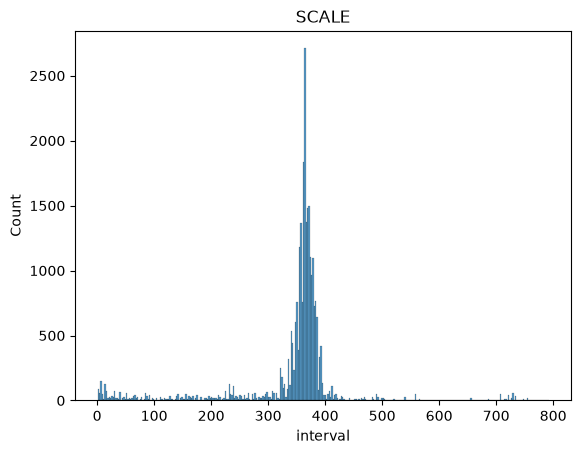

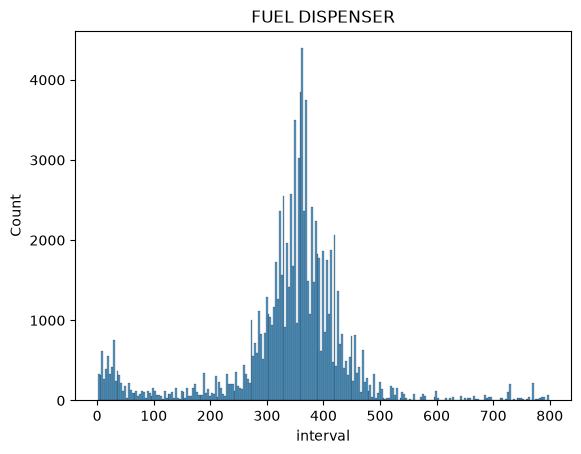

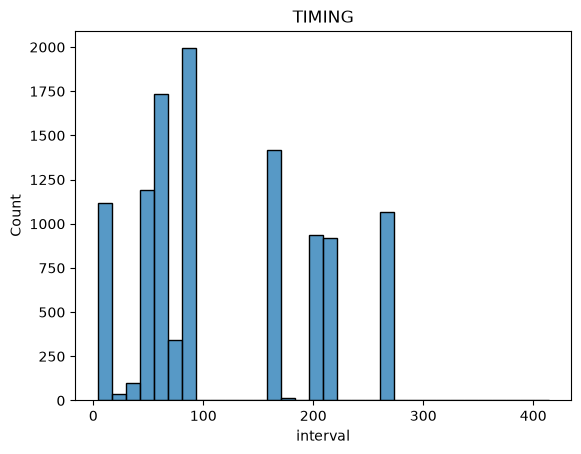

In [42]:
for k,v in _41.groupby('device_group'):
    sns.histplot(v, x='interval')
    plt.title(k)
    plt.show();

In [43]:
data.Devices.group_by('inspection_cycle').len().show()

inspection_cycle,len
str,u64
"""12 MONTH""",23784
"""36 MONTH""",3546
"""60 MONTH""",11969
"""OTHER""",1
null,2


In [215]:
pl.DataFrame({
    'inspection_cycle': ['12 MONTH', '36 MONTH', '60 MONTH'],
    'months': [12, 36, 60],
}).with_columns(
    cycle=pl.col('months') * datetime.timedelta(days=30.437),
).lazy().join(
    Inspection_Interval, 'inspection_cycle',
).with_columns(
    overdue=pl.col('interval') > pl.col('cycle'),
)

In [216]:
_215.filter(
    pl.col('reinspection') == 'No',
    datetime.timedelta(days=0) < pl.col('interval'),
    pl.col('interval') < datetime.timedelta(days=800),
    pl.col('deleted').not_(),
).with_columns(
    cs.duration().dt.total_days(),
).collect().to_pandas()

,inspection_cycle,months,cycle,_id,inspection_id,store_id,device_id,date,result,reinspection,...,pump,grade,capacity,remarks,deleted,next_date,next_date_upcoming,interval,interval_upcoming,overdue
0,12 MONTH,12,365,89532970,47979,32200,13263,2016-01-07,Pass,No,...,NaN,NaN,30 LB,NaN,False,2017-01-11,2017-01-11,370,370,True
1,12 MONTH,12,365,89532974,47983,40195,18365,2016-01-06,Pass,No,...,1,NaN,30 LB,NaN,False,2017-01-04,2017-01-04,364,364,False
2,12 MONTH,12,365,89532976,47985,31963,13371,2016-01-06,Pass,No,...,NaN,NaN,1200 G,NaN,False,2017-01-04,2017-01-04,364,364,False
3,12 MONTH,12,365,89532978,47987,31272,12569,2016-01-06,Pass,No,...,BR,NaN,30 LB,NaN,False,2017-01-04,2017-01-04,364,364,False
4,12 MONTH,12,365,89532980,47989,31522,10680,2016-01-06,Pass,No,...,R,NaN,30 LB,NaN,False,2017-01-05,2017-01-05,365,365,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146468,12 MONTH,12,365,89594620,110431,32034,24252,2019-01-03,Pass,No,...,D,NaN,30 LB,NaN,False,2019-01-10,2019-01-10,7,7,False
146469,12 MONTH,12,365,89594624,110435,32034,24249,2019-01-03,Pass,No,...,PF,NaN,30 LB,NaN,False,2019-01-10,2019-01-10,7,7,False
146470,12 MONTH,12,365,89594626,110437,32034,24474,2019-01-03,Pass,No,...,D,NaN,30 LB,NaN,False,2019-01-10,2019-01-10,7,7,False
146471,12 MONTH,12,365,89594630,110441,31939,12767,2019-01-11,Pass,No,...,NaN,NaN,5 LB,NaN,False,2020-01-30,2020-01-30,384,384,True


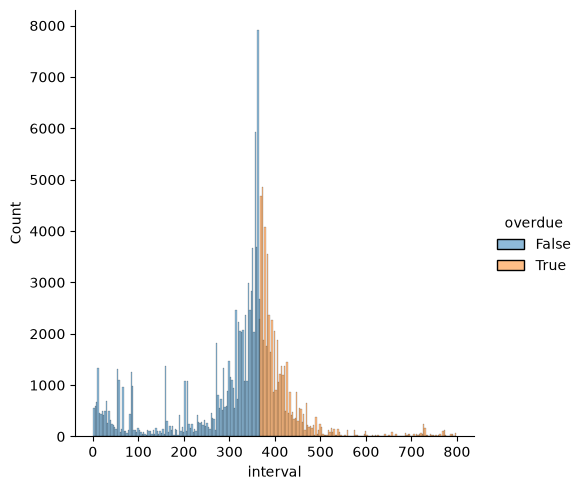

In [219]:
sns.displot(_216, x='interval', hue='overdue')

In [226]:
_215.join(Stores, 'store_id', suffix='__right')

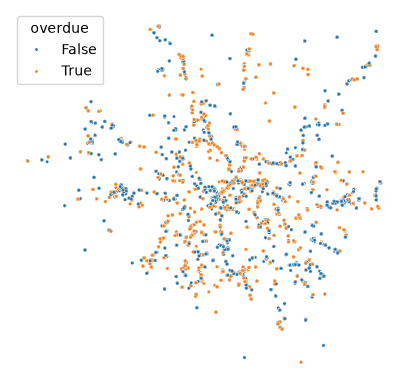

In [281]:
sns.scatterplot(
    _226.filter(pl.col('overdue').is_not_null()).collect().to_pandas(),
    # _226.collect().to_pandas(),
    x='longitude',
    y='latitude',
    hue='overdue',
    s=5,
)
plt.gca().set_aspect(1.314)
plt.gca().set_axis_off()

In [239]:
_226.group_by('zip','overdue').len().pivot('overdue',[False,True],index='zip').with_columns(rate=pl.col('false')/(pl.col('false')+pl.col('true'))).sort('rate').show(1000)

zip,false,true,rate
str,u64,u64,f64
"""15064""",2,null,null
"""15282""",null,null,null
"""15088""",null,null,null
null,null,null,null
"""15063""",5,null,null
"""19002""",null,null,null
"""15007""",2,4,0.333333
"""15225""",351,537,0.39527
"""15034""",78,114,0.40625


<Axes: xlabel='interval', ylabel='Count'>

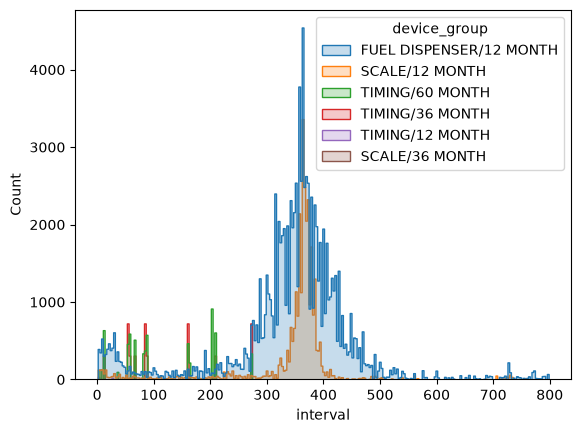

In [162]:
sns.histplot(_161, x='interval', hue='device_group', element='step')

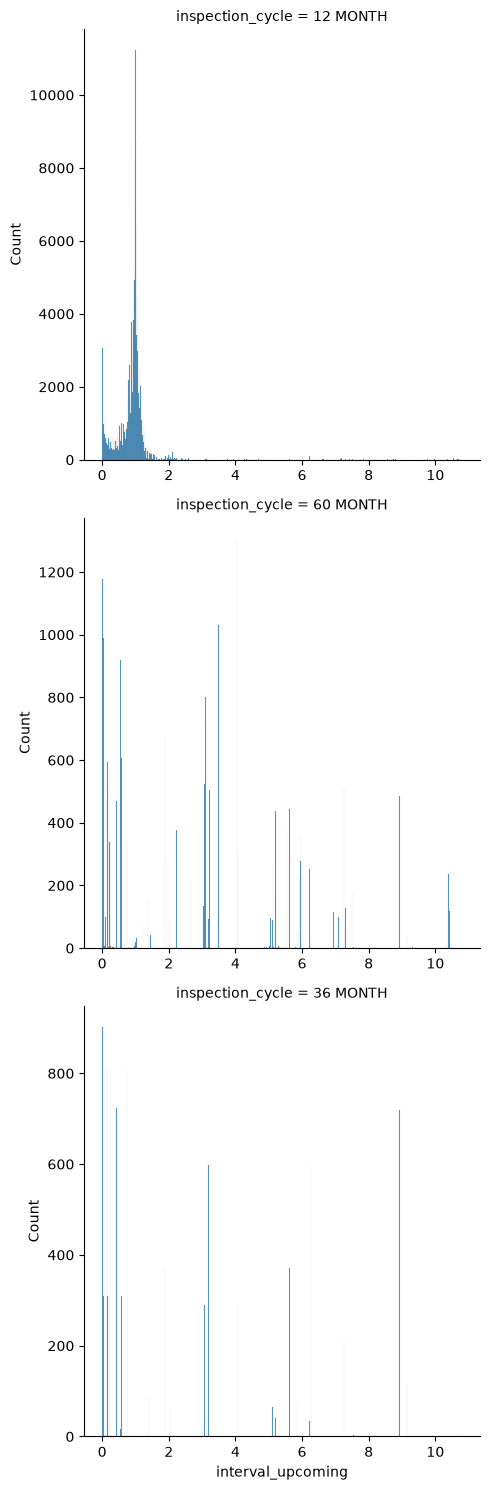

In [26]:
g=sns.displot(_23,x='interval_upcoming',row='inspection_cycle',facet_kws=dict(sharex=False,sharey=False))

<Axes: xlabel='interval', ylabel='Count'>

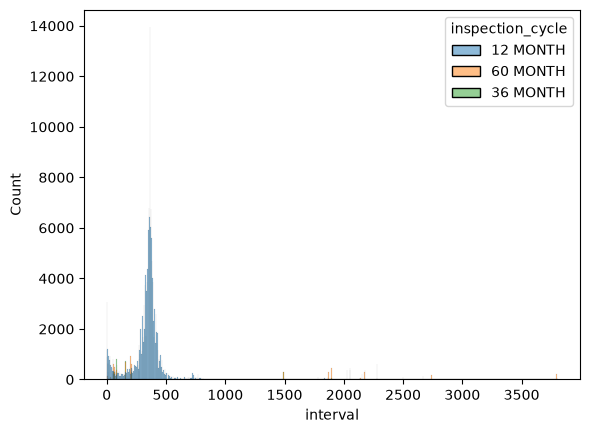

In [4]:
sns.histplot(_3,x='interval',hue='inspection_cycle')

In [2]:
Inspection_Interval.sort('device_id', 'date').drop('result', 'reinspection').collect().show(100)

_id,inspection_id,store_id,device_id,date,interval
i64,i64,i64,i64,date,duration[μs]
89546478,61501,33113,1,2016-08-18,215d
89555231,70260,33113,1,2017-03-21,413d
89580105,95902,33113,1,2018-05-08,391d
89603758,119569,33113,1,2019-06-03,408d
89625841,141657,33113,1,2020-07-15,300d
89637968,153788,33113,1,2021-05-11,409d
89657359,173187,33113,1,2022-06-24,12d
89657568,173396,33113,1,2022-07-06,376d
89677175,193008,33113,1,2023-07-17,32d


In [79]:
NextInspections.count().show()

device_id,next_date
u64,u64
39302,34232


In [80]:
NextInspections.describe()

statistic,device_id,next_date
str,f64,str
"""count""",39302.0,"""34232"""
"""null_count""",0.0,"""5070"""
"""mean""",20104.902193,"""2026-04-27 13:03:28.646880"""
"""std""",11529.482041,null
"""min""",1.0,"""2017-01-05"""
"""25%""",10030.0,"""2025-12-19"""
"""50%""",20259.0,"""2027-04-30"""
"""75%""",30084.0,"""2027-10-06"""
"""max""",39909.0,"""2031-10-22"""


array([[<Axes: title={'center': 'next_date'}>]], dtype=object)

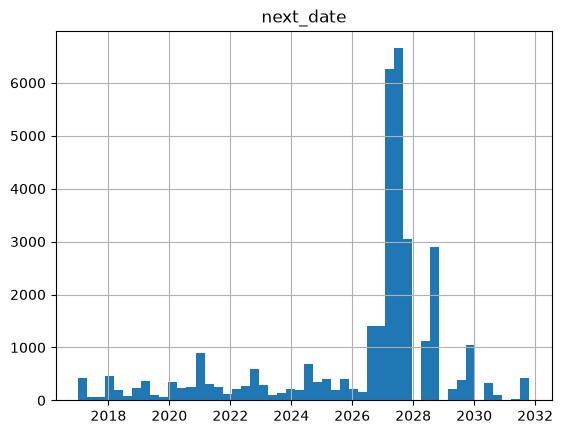

In [86]:
NextInspections.collect().to_pandas().hist('next_date', bins=50)

In [103]:
NextInspections.sort('next_date').filter(
    date.today() < pl.col('next_date'),
    pl.col('next_date') < date.today()+datetime.timedelta(days=30),
).join(Devices, 'device_id').show()

device_id,next_date,_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset
i64,date,i64,i64,str,cat,str,str,str,str,str,str,str,str,bool,str
39044,2026-11-14,11580080,41078,"""DIGITAL""","""SCALE""","""HOBART""",null,"""451292683""","""D""",null,"""30 LB""","""12 MONTH""",null,false,"""12mo"""
39045,2026-11-14,11580081,41078,"""DIGITAL""","""SCALE""","""METTLER""",null,"""102668""","""CURB""",null,"""30 LB""","""12 MONTH""",null,false,"""12mo"""
39353,2026-11-03,11580373,40814,"""DIGITAL""","""SCALE""","""ADAM""",null,"""3200234""",null,null,"""100 G""","""12 MONTH""",null,false,"""12mo"""
39354,2026-11-03,11580374,40814,"""DIGITAL""","""SCALE""","""ADAM""",null,"""00050""",null,null,"""100 G""","""12 MONTH""",null,false,"""12mo"""
39412,2026-11-20,11580379,41229,"""DIGITAL""","""SCALE""","""BROMECH""",null,"""NSN""",null,null,"""88 LB""","""12 MONTH""",null,false,"""12mo"""


In [109]:
NextInspectionsByStore = NextInspections.sort('next_date').filter(
    date.today() < pl.col('next_date'),
    pl.col('next_date') < date.today()+datetime.timedelta(days=30),
).join(Devices, 'device_id').group_by('store_id').agg(pl.len(), pl.first('next_date'))

In [110]:
NextInspectionsByStore.show()

store_id,len,next_date
i64,u64,date
41078,32,2026-11-14
41162,2,2026-11-13
40814,13,2026-11-03
40684,1,2026-11-17
41229,1,2026-11-20


In [112]:
NextInspectionsByStore.join(Stores.select('store_id','zip'), 'store_id').show()

store_id,len,next_date,zip
i64,u64,date,str
30429,2,2026-11-16,"""15131"""
30280,2,2026-11-18,"""15215"""
30961,1,2026-11-17,"""15137"""
31570,1,2026-11-16,"""15209"""
31633,1,2026-11-20,"""15223"""


In [123]:
Stores.show()

_id,store_id,store_name,address,mailing_city,state,zip,municipality,neighborhood,longitude,latitude,business_phone,alternate_phone,price_verification,fuel_dispenser,scale,timing,oob,unit,shopping_center,new_municipality
i64,i64,str,str,str,str,str,str,str,f64,f64,str,str,bool,bool,bool,bool,bool,str,str,str
2036431,29999,"""SANDY CREEK SUPPLY""","""140 SANDY CREEK RD""","""VERONA""","""PA""","""15147""","""VERONA""",null,-79.851046,40.481883,"""412-793-8303""",null,false,false,false,false,true,null,null,"""PENNHILLS"""
2036432,30000,"""MIMI MOTHERHOOD MATERNITY""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""412-666-0644""",null,false,false,false,false,true,null,"""MONROEVILLE MALL""","""MONROEVILLE"""
2036433,30003,"""EXPRESS FACTORY""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 856-9353""",null,false,false,false,false,true,null,"""MONROEVILLE MALL""","""MONROEVILLE"""
2036434,30004,"""AMERICAN EAGLE OUTFITTERS""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 372-9092""",null,true,false,false,false,false,null,"""MONROEVILLE MALL ""","""MONROEVILLE"""
2036435,30005,"""GNC""","""200 MALL CIRCLE DR""","""MONROEVILLE""","""PA""","""15146""","""MONROEVILLE""",null,-79.79603,40.42926,"""(412) 372-9600""",null,false,false,false,false,true,null,"""MONROEVILLE MALL""","""MONROEVILLE"""


In [132]:
NextInspectionsByStore.join(
    Stores.sql(
        "select store_id,coalesce(shopping_center, neighborhood, new_municipality, municipality) as place from self",
    ),
    'store_id').group_by(
    'place', 'next_date',
).agg(pl.sum('len').alias('device_id_count'), pl.count('store_id').alias('store_id_count')).sort('next_date').show(1000)

place,next_date,device_id_count,store_id_count
str,date,u64,u64
"""PITTSBURGH""",2026-10-29,1,1
"""ARSENAL""",2026-10-30,2,2
"""BELLEVUE""",2026-10-30,1,1
"""OHARA""",2026-11-03,14,2
"""N. VERSAILLES""",2026-11-03,3,1
"""FOX CHAPEL""",2026-11-03,1,1
"""PITTSBURGH""",2026-11-03,4,1
"""EAST LIBERTY""",2026-11-03,1,1
"""VERONA""",2026-11-03,2,1


In [ ]:
NextInspectionsByStore.join(
    Stores.sql(
        "select store_id,coalesce(shopping_center, neighborhood, new_municipality, municipality) as place from self",
    ),
    'store_id').group_by(
    'place', 'next_date',
).agg(pl.sum('len').alias('device_id_count'), pl.count('store_id').alias('store_id_count')).sort('next_date').show(1000)

In [163]:
NextInspections.filter(
    pl.col('next_date').is_between(date(2026,11,1),date(2026,11,14)),
).join(Devices.select('store_id', 'device_id'), 'device_id').join(
    Stores, 'store_id',
).group_by('store_id', 'store_name', 'next_date', 'longitude', 'latitude').len().collect()

store_id,store_name,next_date,longitude,latitude,len
i64,str,date,f64,f64,u64
32563,"""BOOK COUNTRY""",2026-11-05,-79.843054,40.329648,2
32905,"""LAUNDRY BASKET""",2026-11-12,-80.036343,40.397823,1
32940,"""UPMC EAST CAFETERIA""",2026-11-07,-79.760533,40.436937,2
33093,"""BOULEVARD LAUNDROMAT""",2026-11-12,-80.020957,40.394142,2
33111,"""DUNHAM SPORTS""",2026-11-07,-79.78941,40.434642,1
…,…,…,…,…,…
40826,"""ROYAL JEWELRY""",2026-11-14,-80.165957,40.453622,1
40837,"""SUNBELT RENTALS""",2026-11-12,-80.016503,40.348629,1
41088,"""MY FAVORITE SWEET SHOPPE""",2026-11-12,-80.084754,40.408929,3


In [167]:
_163.to_pandas()

,store_id,store_name,next_date,longitude,latitude,len
0,32563,BOOK COUNTRY,2026-11-05,-79.843054,40.329648,2
1,32905,LAUNDRY BASKET,2026-11-12,-80.036343,40.397823,1
2,32940,UPMC EAST CAFETERIA,2026-11-07,-79.760533,40.436937,2
3,33093,BOULEVARD LAUNDROMAT,2026-11-12,-80.020957,40.394142,2
4,33111,DUNHAM SPORTS,2026-11-07,-79.789410,40.434642,1
...,...,...,...,...,...,...
66,40826,ROYAL JEWELRY,2026-11-14,-80.165957,40.453622,1
67,40837,SUNBELT RENTALS,2026-11-12,-80.016503,40.348629,1
68,41088,MY FAVORITE SWEET SHOPPE,2026-11-12,-80.084754,40.408929,3
69,41225,BREEZE,2026-11-13,NaN,NaN,3


In [ ]:
# plt.scatter('longitude', 'latitude', data=_167);
for _, d in _167.iterrows():
    plt.text(d['longitude'], d['latitude'], s=d['len']);
plt.gca().set_aspect(1.314);
plt.gca().set_axis_off();